# 05 - Model Evaluation

Loads the saved model artifact and evaluates it in full on the held-out test split: regression metrics (MAE/MSE/RMSE/R2) and classification metrics (accuracy/precision/recall/F1/confusion matrix).

In [1]:
import sys, os
sys.path.append(os.path.abspath('../src'))
os.chdir('..')  # so relative paths like 'data/raw/students.csv' resolve
import warnings
warnings.filterwarnings('ignore')


In [2]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

from data_preprocessing import load_raw_data, clean_data, get_features_and_target
from feature_engineering import categorize_performance

artifact = joblib.load('models/student_performance_model.joblib')
df = clean_data(load_raw_data())
X, y_reg = get_features_and_target(df)
_, X_test, _, y_reg_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=artifact['random_state'])
y_clf_test = y_reg_test.apply(categorize_performance)

clean_data: (505, 11) -> (500, 11) (removed 5 rows: duplicates / missing target)


## Regression evaluation

In [3]:
reg_preds = artifact['regressor'].predict(X_test)
mae = mean_absolute_error(y_reg_test, reg_preds)
mse = mean_squared_error(y_reg_test, reg_preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_reg_test, reg_preds)
print(f"Model: {artifact['regressor_name']}")
print(f'MAE : {mae:.4f}')
print(f'MSE : {mse:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R^2 : {r2:.4f}')

Model: LinearRegression
MAE : 5.0226
MSE : 39.5646
RMSE: 6.2900
R^2 : 0.5483


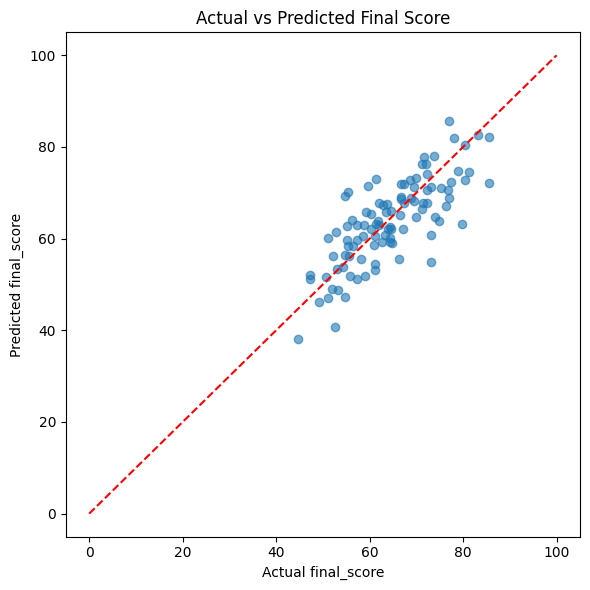

In [4]:
plt.figure(figsize=(6,6))
plt.scatter(y_reg_test, reg_preds, alpha=0.6)
plt.plot([0,100],[0,100],'r--')
plt.xlabel('Actual final_score')
plt.ylabel('Predicted final_score')
plt.title('Actual vs Predicted Final Score')
plt.tight_layout()
plt.show()

## Classification evaluation

In [5]:
labels = artifact['performance_categories']
clf_preds = artifact['classifier'].predict(X_test)
print(f"Model: {artifact['classifier_name']}")
print('Accuracy :', round(accuracy_score(y_clf_test, clf_preds), 4))
print('Precision:', round(precision_score(y_clf_test, clf_preds, average='weighted', zero_division=0), 4))
print('Recall   :', round(recall_score(y_clf_test, clf_preds, average='weighted', zero_division=0), 4))
print('F1 Score :', round(f1_score(y_clf_test, clf_preds, average='weighted', zero_division=0), 4))
print()
print(classification_report(y_clf_test, clf_preds, labels=labels, zero_division=0))

Model: LogisticRegression
Accuracy : 0.76
Precision: 0.7616
Recall   : 0.76
F1 Score : 0.7594

                   precision    recall  f1-score   support

Needs Improvement       0.29      0.50      0.36         4
          Average       0.85      0.82      0.83        67
             Good       0.68      0.70      0.69        27
        Excellent       0.00      0.00      0.00         2

         accuracy                           0.76       100
        macro avg       0.45      0.51      0.47       100
     weighted avg       0.76      0.76      0.76       100



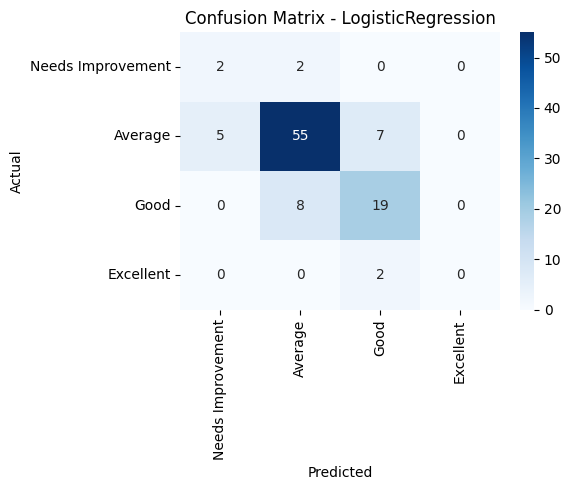

In [6]:
cm = confusion_matrix(y_clf_test, clf_preds, labels=labels)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f"Confusion Matrix - {artifact['classifier_name']}")
plt.tight_layout()
plt.show()

## Summary

These are the actual, reproducible metrics obtained by running this project's pipeline on the synthetic dataset (fixed `random_state=42`). They are **not** claimed to represent real-world student performance prediction accuracy - see the README's Dataset Description section for the real/synthetic-data disclosure.